[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch13-simple_workbook.ipynb)

# A frozen table and a changing context

Count the words of Pride and Prejudice once and freeze the counts. After
not, the next word could be almost anything; after i do not, it is most
often know. Nothing in the table changed, only the context, and a prompt
changes a language model the same way. How much does a word of context
narrow the guess? Can a few words tell which volume a passage comes from?
Do ten frozen tables that vote guess the next word better than one?

In [1]:
#@title Setup: run this cell first
import math
import os
import re
import urllib.request
from collections import Counter, defaultdict
from itertools import accumulate

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# Volume one is chapters 1 to 23 and volume three chapters 43 to 61. Ten tables read chapters 1 to 50, table k every
# chapter whose number leaves k - 1 after division by 10, and guess the words of chapters 51 to 61.
FIRST_ONE, LAST_ONE, FIRST_THREE, LAST_THREE = 1, 23, 43, 61
TABLES, TEST_FIRST = 10, 51
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


chapters = load_novel()
follow = defaultdict(Counter)  # a context of one, two or three words -> the counts of the word after it
for c in chapters:
    for i, n in ((i, n) for i in range(1, len(c)) for n in range(1, min(3, i) + 1)):
        follow[tuple(c[i - n:i])][c[i]] += 1
counts = [Counter(c) for c in chapters]
one = sum((counts[i - 1] for i in range(FIRST_ONE, LAST_ONE + 1)), Counter())
three = sum((counts[i - 1] for i in range(FIRST_THREE, LAST_THREE + 1)), Counter())
slots = len({w for c in chapters for w in c}) + 1  # every word of the novel and one slot for the rest


# Step 1: the next-word distribution after the last one, two and three words of a phrase, from the frozen counts.
def entropy(cnt):  # bits
    return -sum(v / sum(cnt.values()) * math.log2(v / sum(cnt.values())) for v in cnt.values())


def show_context(phrase):
    words = phrase.split() if type(phrase) is str else []
    if not 1 <= len(words) <= 3 or not follow[tuple(words)]:
        raise Refused(f"PHRASE is {phrase!r}: PHRASE takes one to three lowercase words the novel uses in that order, "
                      "such as 'i do not'.")
    rows = [(" ".join(words[-k:]), follow[tuple(words[-k:])]) for k in range(1, len(words) + 1)]
    share = lambda cnt, w: cnt[w] / sum(cnt.values())  # noqa: E731
    for ctx, cnt in rows:
        print(f"after '{ctx}': {entropy(cnt):.2f} bits; " + ", ".join(f"{w} {share(cnt, w):.3f}" for w, _ in cnt.most_common(3)))
    fig, ax = plt.subplots(figsize=(6, 0.5 * len(rows) + 1.2), layout="constrained")
    b = ax.barh([r[0] for r in rows], [entropy(r[1]) for r in rows], color="C0")
    top = [r[1].most_common(1)[0][0] for r in rows]
    ax.bar_label(b, labels=[f"{entropy(r[1]):.2f} bits, then '{t}' {share(r[1], t):.3f}" for r, t in zip(rows, top)],
                 padding=2, fontsize=8)
    ax.set(title="spread of the next word, frozen counts", xlabel="entropy, bits", xlim=(0, 14), ylim=(len(rows) - 0.4, -0.6))
    plt.show()


# Step 2: the posterior on volume three after each word of a window. Both volumes' counts leave the chapter examined
# out, so no word is counted in the table that judges it; add-one smoothing gives every word a rate in both.
def log_ratio(chapter):
    if type(chapter) is not int or not (FIRST_ONE <= chapter <= LAST_ONE or FIRST_THREE <= chapter <= LAST_THREE):
        raise Refused(f"CHAPTER is {chapter!r}: CHAPTER takes a chapter of volume one or three, 1 to 23 or 43 to 61.")
    i = chapter
    a, b = (one - counts[i - 1], three) if i <= LAST_ONE else (one, three - counts[i - 1])
    na, nb = sum(a.values()) + slots, sum(b.values()) + slots
    return lambda w: math.log((b[w] + 1) / nb) - math.log((a[w] + 1) / na)


def walk(lr, words):  # the posterior on volume three after each word, from a prior of 0.5: the log-odds add up
    return [1 / (1 + math.exp(-x)) for x in accumulate(map(lr, words))]


def path(chapter, n):
    return walk(log_ratio(chapter), chapters[chapter - 1][:whole("WORDS", n, 1, 500)])


def show_volume(chapter, n):
    ps = path(chapter, n)
    print(f"chapter {chapter}: posterior on volume three after 1 word {ps[0]:.3f}, after {len(ps)} words {ps[-1]:.3f}")
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    ax.plot(range(1, len(ps) + 1), ps, color="C3")
    ax.axhline(0.5, color="0.5", ls="--")
    ax.set(title=f"chapter {chapter}, one word at a time; dashed, the prior 0.5", xlabel="words read",
           ylabel="posterior on volume three", ylim=(0, 1))
    plt.show()


# Step 3: each table guesses the word after a word as the word that followed it most often in its chapters, and its
# most common word after a word it never saw. Ties go to the pair counted first, so every run gives the same guesses.
def guesser(numbers):
    pairs = Counter(p for i in numbers for p in zip(chapters[i - 1], chapters[i - 1][1:]))
    best = {}
    for (a, b), n in pairs.items():
        if a not in best or n > pairs[a, best[a]]:
            best[a] = b
    return best, Counter(w for i in numbers for w in chapters[i - 1]).most_common(1)[0][0]


tables = [guesser([i for i in range(1, TEST_FIRST) if (i - 1) % TABLES == k]) for k in range(TABLES)]
full = guesser(range(1, TEST_FIRST))
test = [p for c in chapters[TEST_FIRST - 1:] for p in zip(c, c[1:])]
guesses = [[t[0].get(a, t[1]) for t in tables] for a, _ in test]
alone = 100 * sum(full[0].get(a, full[1]) == b for a, b in test) / len(test)  # one table of chapters 1 to 50


def rates(k):  # per cent of test words: the vote of the first k tables right; some table right; all k agree and wrong
    whole("K", k, 1, TABLES)
    vote = sum(Counter(g[:k]).most_common(1)[0][0] == b for g, (_, b) in zip(guesses, test))
    some = sum(b in g[:k] for g, (_, b) in zip(guesses, test))
    wrong = sum(len(set(g[:k])) == 1 and g[0] != b for g, (_, b) in zip(guesses, test))
    return [100 * x / len(test) for x in (vote, some, wrong)]


def show_vote(k):
    ks, votes = range(1, whole("GUESSERS", k, 1, TABLES) + 1), [rates(j)[0] for j in range(1, k + 1)]
    print(f"{len(test):,} test words: table 1 {votes[0]:.2f} per cent, vote of {k} {votes[-1]:.2f}, one table of all {alone:.2f}")
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    ax.plot(ks, votes, "o-", color="C3", label="vote of the first K tables")
    ax.axhline(alone, color="0.5", ls="--", label=f"one table of all {TEST_FIRST - 1} chapters")
    ax.set(title=f"next word of chapters {TEST_FIRST} to {LAST_THREE}, guessed from the word before", xlabel="tables K",
           ylabel="right, per cent", ylim=(0, 15))
    ax.legend(loc="lower right")
    plt.show()

## 1. Frozen counts, a changing context

The cell counts, over the whole novel, which word follows the last one, two
and three words of a phrase, and prints how spread out the next word is, in
bits. The counts are fixed before the cell runs: only the context changes.
Run it for i do not. Then set `PHRASE` to `"said mr"`.

after 'not': 7.61 bits; be 0.063, to 0.046, have 0.031
after 'do not': 5.25 bits; know 0.177, think 0.056, make 0.048
after 'i do not': 4.04 bits; know 0.306, believe 0.081, think 0.081


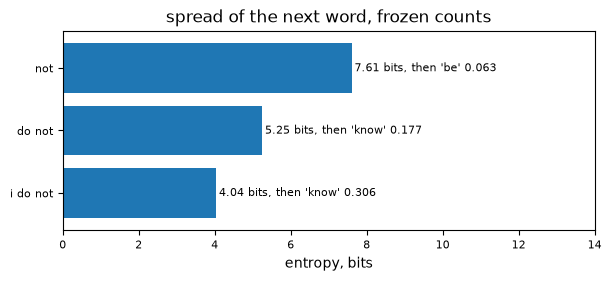

In [2]:
PHRASE = "i do not"
show_context(PHRASE)

### Solution

In [3]:
h = [entropy(follow[c]) for c in (("not",), ("do", "not"), ("i", "do", "not"), ("mr",), ("said", "mr"))]
know = follow["i", "do", "not"]["know"] / sum(follow["i", "do", "not"].values())
bennet = follow["said", "mr"]["bennet"] / sum(follow["said", "mr"].values())
display(Markdown(f"After not the next word is spread over {h[0]:.2f} bits, after do not {h[1]:.2f} and after i do not "
                 f"{h[2]:.2f}, where know takes {know:.3f}. After mr it is {h[3]:.2f} bits and after said mr {h[4]:.2f}, where "
                 f"bennet takes {bennet:.3f}. No count changed between the rows; each extra word of context selects fewer of "
                 f"the counts, as a prompt selects what a model with frozen weights predicts."))

After not the next word is spread over 7.61 bits, after do not 5.25 and after i do not 4.04, where know takes 0.306. After mr it is 3.23 bits and after said mr 1.74, where bennet takes 0.588. No count changed between the rows; each extra word of context selects fewer of the counts, as a prompt selects what a model with frozen weights predicts.

## 2. Words as evidence about the volume

Read in-context learning as inference over tasks: each demonstration is
evidence about the task the prompt shows. Here the two tasks are the
novel's first and third volumes, chapters 1 to 23 and 43 to 61. The cell
counts the words of each volume, leaving out the chapter examined, then
reads that chapter one word at a time; each word multiplies the odds on
volume three by how much likelier it is there. Run it for the first 50
words of chapter 1. Then set `CHAPTER` to 46.

chapter 1: posterior on volume three after 1 word 0.534, after 50 words 0.271


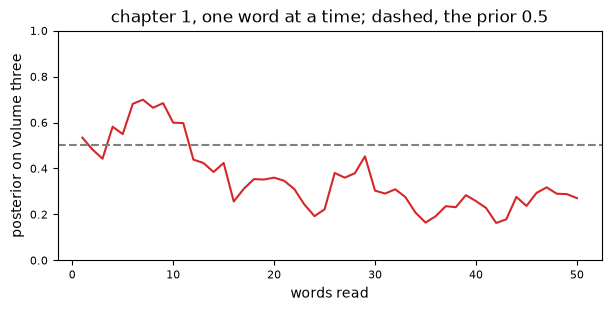

In [4]:
CHAPTER = 1
WORDS = 50
show_volume(CHAPTER, WORDS)

### Solution

In [5]:
moves, hits, runs = [0.0] * 20, [0, 0], 0
for i in list(range(FIRST_ONE, LAST_ONE + 1)) + list(range(FIRST_THREE, LAST_THREE + 1)):
    lr, c = log_ratio(i), chapters[i - 1]
    for s in range(0, len(c) - 19, 20):
        ps, runs = [0.5] + walk(lr, c[s:s + 20]), runs + 1
        moves = [m + abs(ps[j + 1] - ps[j]) for j, m in enumerate(moves)]
        hits = [h + ((ps[j] > 0.5) == (i >= FIRST_THREE)) for h, j in zip(hits, (1, 20))]
display(Markdown(f"Chapter 1's first 50 words leave {path(1, 50)[-1]:.3f} on volume three, so they point to volume one, "
                 f"and chapter 46's leave {path(46, 50)[-1]:.3f}. Over every window of both volumes, each chapter left out of "
                 f"its own counts and cut into windows of 20 words, the first word names the right volume "
                 f"{100 * hits[0] / runs:.1f} per cent of the time and all 20 words {100 * hits[1] / runs:.1f}. The first word "
                 f"moves the posterior by {moves[0] / runs:.3f} on average and the twentieth by {moves[19] / runs:.3f}: the first moves it most."))

Chapter 1's first 50 words leave 0.271 on volume three, so they point to volume one, and chapter 46's leave 0.999. Over every window of both volumes, each chapter left out of its own counts and cut into windows of 20 words, the first word names the right volume 51.5 per cent of the time and all 20 words 65.3. The first word moves the posterior by 0.071 on average and the twentieth by 0.039: the first moves it most.

## 3. A vote over frozen tables

Self-consistency samples several chains and keeps the most common answer.
Here ten tables each read every tenth chapter of chapters 1 to 50, and each
guesses the next word of chapters 51 to 61 from the word before it. A vote of
the first K tables keeps the guess most of them make. Run the cell. Does the
vote beat one table, and does it reach one table that reads all 50
chapters?

24,124 test words: table 1 8.74 per cent, vote of 10 10.55, one table of all 12.12


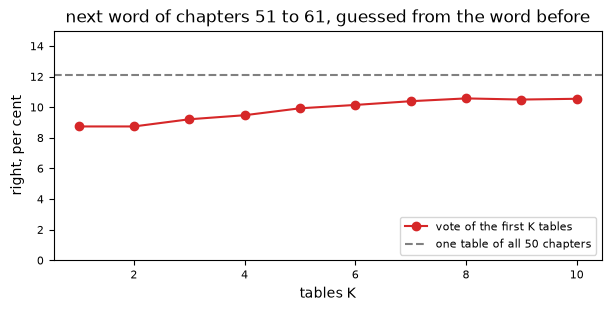

In [6]:
GUESSERS = 10
show_vote(GUESSERS)

### Solution

In [7]:
singles = [100 * sum(g[k] == b for g, (_, b) in zip(guesses, test)) / len(test) for k in range(TABLES)]
display(Markdown(f"One table guesses {min(singles):.2f} to {max(singles):.2f} per cent of the {len(test):,} test words right, "
                 f"and the vote of all ten {rates(10)[0]:.2f}. One table that reads all 50 chapters gets {alone:.2f}: the vote gains on "
                 f"each of its members and stays below the table that pools their counts. With thousands of possible next "
                 f"words, the right one wins a vote only when it is the most common guess."))

One table guesses 8.44 to 9.62 per cent of the 24,124 test words right, and the vote of all ten 10.55. One table that reads all 50 chapters gets 12.12: the vote gains on each of its members and stays below the table that pools their counts. With thousands of possible next words, the right one wins a vote only when it is the most common guess.

## Appendix. Right guesses a vote cannot keep

A vote can only return a guess some table makes, and where every table
makes the same wrong guess no vote helps. The cell counts, for the first K
tables, the test words some table guesses right, the words the vote gets
right and the words on which all K tables agree on a wrong guess.

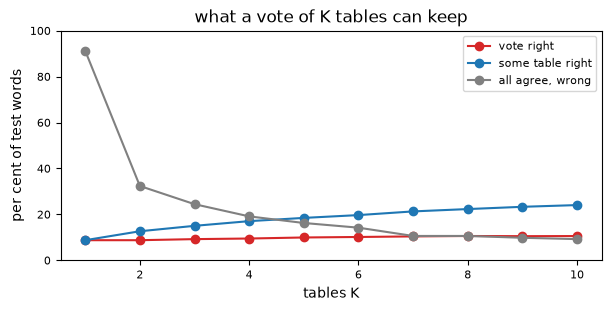

In [8]:
rows = [rates(k) for k in range(1, TABLES + 1)]
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
for col, (label, colour) in enumerate((("vote right", "C3"), ("some table right", "C0"), ("all agree, wrong", "0.5"))):
    ax.plot(range(1, TABLES + 1), [r[col] for r in rows], "o-", color=colour, label=label)
ax.set(title="what a vote of K tables can keep", xlabel="tables K", ylabel="per cent of test words", ylim=(0, 100))
ax.legend()
plt.show()

**Exercise.** Set `K` to 3: on what share of the test words do all three
tables agree on a wrong word?

In [9]:
K = 10
print("{} tables: vote right {:.2f} per cent, some table right {:.2f}, all agree and wrong {:.2f}".format(K, *rates(K)))

10 tables: vote right 10.55 per cent, some table right 24.04, all agree and wrong 9.21


### Solution

In [10]:
three, ten = rates(3), rates(10)
display(Markdown(f"Three tables all make the same wrong guess on {three[2]:.2f} per cent of the test words and ten tables on "
                 f"{ten[2]:.2f}; on those words no vote can be right. With ten tables some table is right on {ten[1]:.2f} per "
                 f"cent, and the vote keeps {ten[0]:.2f}: a right guess that only a few tables make loses the vote."))

Three tables all make the same wrong guess on 24.43 per cent of the test words and ten tables on 9.21; on those words no vote can be right. With ten tables some table is right on 24.04 per cent, and the vote keeps 10.55: a right guess that only a few tables make loses the vote.